# Reproduce Fig.2 Part 1 - GEM 1st-pass
This notebook illustrate how to do GEM 1st-pass.

We could do multi-pass in a single notebook; however, too many posthoc visualization (see below) cause github codespace's autosave to run out of memory. Therefore, to visualize post-hoc, so that readers can better understand Appendix B in the paper, we separate 1st-pass and later passes to two notebooks. Readers can see the 2nd and final passes at `fig2_posthoc.ipynb` . 

### NOTE on reproducing Tables 2 and 3
This notebook can be used to reproduce Tables 2 and 3 (Appendix D.1) as well, by simply varyig `(RIDGE_X0, strict_Y_int)` as detailed in Table 1. Then make a loop over them.

Set up all configurations

In [ ]:
## CONFIG
GH_NODES = 200 # Gauss-Hermit nodes for marginal-prob integration
MAX_ITER = 200 # Max GEM iterations

OPTIMAL_KAPPA_INIT = True # use our default init for kappa

# regularization parameters
RIDGE_KAPPA = 0.1
RIDGE_GAMMA = 0.1
RIDGE_B = 0.1
RIDGE_A = 0.5
RIDGE_X0 = 1000
MU_GAMMA = 0.1
MU_KAPPA = -0.01

KAPPA_MAX=-0.00001 # bound for kappa

strict_Y_int = False # False: allow soft-score for Y[i,j], True: only 0/1 score

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import joblib

# Graphical configs
# 1. Reset seaborn to baseline
sns.set_style('whitegrid')
sns.set_context('paper') # Remove font_scale!

# 2. Hardcode the absolute font sizes for publication
plt.rcParams.update({
    'font.size': 9,             # Global baseline
    'figure.titlesize': 9,      # Global figure titles (Added)
    'axes.titlesize': 10,       # Title of the subplot (ax.set_title)
    'axes.labelsize': 9,        # X and Y axis labels
    'xtick.labelsize': 8,       # Numbers on the X axis
    'ytick.labelsize': 8,       # Numbers on the Y axis
    'legend.fontsize': 8,       # Legend text
    'legend.title_fontsize': 8  # Legend title
})

### Data loading

In [3]:
B_coding = pd.read_csv('data/B_coding.csv', index_col=0)
B_language = pd.read_csv('data/B_language.csv', index_col=0)
B_reasoning = pd.read_csv('data/B_reasoning.csv', index_col=0)
B_math = pd.read_csv('data/B_math.csv', index_col=0)

Y_coding = pd.read_csv('data/Y_coding.csv', index_col=0)
Y_language = pd.read_csv('data/Y_language.csv', index_col=0)
Y_reasoning = pd.read_csv('data/Y_reasoning.csv', index_col=0)
Y_math = pd.read_csv('data/Y_math.csv', index_col=0)

c_coding = pd.read_csv('data/c_coding.csv', index_col=0).set_index('question_id')
c_language = pd.read_csv('data/c_language.csv', index_col=0).set_index('question_id')
c_reasoning = pd.read_csv('data/c_reasoning.csv', index_col=0).set_index('question_id')
c_math = pd.read_csv('data/c_math.csv', index_col=0).set_index('question_id')

In [4]:
B = pd.concat([B_language, B_coding, B_reasoning, B_math],axis=0)
Y = pd.concat([Y_language, Y_coding, Y_reasoning, Y_math],axis=0)
c = pd.concat([c_language, c_coding, c_reasoning, c_math],axis=0)

In [5]:
from reasoning_aware_irt.livebench_utils import reindex
_ = reindex(Y, B, c) # little helper to make sure that all dataframes have exactly the same sorted question_id indices

the model_id Y/B sequence is great!!
the question_id Y/B sequence is great!!
the question_id Y/c sequence is great!!


In [6]:
Y_ij = Y.values
B_ij = B.values.astype(int)
c_i = c.values.squeeze()

print(Y_ij.shape, B_ij.shape)
print(Y_ij.mean(), B_ij.mean())
print(c_i.shape, c_i[:5])

(786, 42) (786, 42)
0.39359059581389527 1310.9940930570701
(786,) [1.e-05 1.e-05 1.e-02 1.e-02 1.e-02]


In [7]:
model_list = np.array(list(B.columns)) 
print(model_list.shape, model_list[-5:])

(42,) ['baidu/ernie-4.5-21b-a3b-thinking' 'allenai/olmo-3-7b-think'
 'qwen/qwen3-30b-a3b-thinking-2507' 'google/gemma-3-27b-it:free'
 'meta-llama/llama-4-scout']


In [8]:
x0_j = np.log1p(B_ij.mean(axis=0)) # budget regularizer (Eq.12 in the paper)

# Evaluate with Reasoning-Aware 3PL's GEM

In [9]:
from reasoning_aware_irt.gem_quad import CalibrationData, CalibrationConfig
from reasoning_aware_irt.gem_quad import ReasoningAware3PLQuadraticCalibrator as ReasoningAware3PLCalibrator

data = CalibrationData(Y_ij=Y_ij, B_ij=B_ij, c_i=c_i)
cfg = CalibrationConfig()
cfg # lets see the default config


CalibrationConfig(gh_nodes=17, max_iter=50, tol=0.0001, seed=0, verbose=True, use_quadratic=True, use_pin_posthoc=False, optimal_kappa=False, tau=0.75, ridge_a=0.001, ridge_b=0.001, ridge_gamma=0.1, ridge_kappa=0.1, mu_a=1.0, mu_b=0.0, mu_gamma=0.2, mu_kappa=-0.02, a_min=0.05, a_max=5.0, gamma_min=0.0, gamma_max=2.0, kappa_min=-2.0, kappa_max=-1e-06, x0_j=None, ridge_x0=0.1)

In [10]:
%%time
init_param_dict = None
    
cfg = CalibrationConfig(
gh_nodes=GH_NODES, max_iter=MAX_ITER, verbose=True,
ridge_kappa=RIDGE_KAPPA, ridge_gamma=RIDGE_GAMMA, 
ridge_a=RIDGE_A, mu_gamma=MU_GAMMA, ridge_b=RIDGE_B,
mu_kappa=MU_KAPPA, kappa_max=KAPPA_MAX, tol=0.001,
ridge_x0=RIDGE_X0, x0_j=x0_j, optimal_kappa=OPTIMAL_KAPPA_INIT)

calibrator = ReasoningAware3PLCalibrator(cfg)
print(cfg)

fit_results = calibrator.fit(data, strict_Y_int=strict_Y_int, init_param_dict=init_param_dict)

CalibrationConfig(gh_nodes=200, max_iter=200, tol=0.001, seed=0, verbose=True, use_quadratic=True, use_pin_posthoc=False, optimal_kappa=True, tau=0.75, ridge_a=0.5, ridge_b=0.1, ridge_gamma=0.1, ridge_kappa=0.1, mu_a=1.0, mu_b=0.0, mu_gamma=0.1, mu_kappa=-0.01, a_min=0.05, a_max=5.0, gamma_min=0.0, gamma_max=2.0, kappa_min=-2.0, kappa_max=-1e-05, x0_j=array([6.35004162, 7.18324597, 6.22199298, 6.10262406, 6.08033779,
       6.31970369, 6.66785474, 5.85850006, 6.37936752, 6.09960554,
       5.78765811, 5.83985728, 5.87082677, 6.04222478, 5.90920246,
       5.76998548, 6.39809522, 6.28766226, 6.65008317, 7.12763448,
       5.98803629, 6.62097526, 5.86790868, 5.80626863, 5.67414051,
       6.33643609, 5.74972923, 6.22767251, 6.46911815, 6.46083781,
       6.523779  , 6.19990512, 5.95793145, 6.17126225, 8.08663221,
       7.75749563, 8.41777231, 8.89141742, 9.26252837, 8.86775312,
       7.09789816, 6.60762969]), ridge_x0=1000)


iter   1  ll=-14990.352849   dLL=nan
iter   2  ll=-13870.565711   dLL=nan
iter   3  ll=-13824.018191   dLL=4.655e+01
iter   4  ll=-13809.730371   dLL=1.429e+01
iter   5  ll=-13803.308479   dLL=6.422e+00
iter   6  ll=-13799.856216   dLL=3.452e+00
iter   7  ll=-13796.763164   dLL=3.093e+00
iter   8  ll=-13794.164895   dLL=2.598e+00
iter   9  ll=-13792.684221   dLL=1.481e+00
iter  10  ll=-13791.627122   dLL=1.057e+00
iter  11  ll=-13791.000348   dLL=6.268e-01
iter  12  ll=-13790.379765   dLL=6.206e-01
iter  13  ll=-13789.964867   dLL=4.149e-01
iter  14  ll=-13789.147421   dLL=8.174e-01
iter  15  ll=-13789.008614   dLL=1.388e-01
iter  16  ll=-13788.727075   dLL=2.815e-01
iter  17  ll=-13788.443196   dLL=2.839e-01
iter  18  ll=-13788.309593   dLL=1.336e-01
iter  19  ll=-13787.962896   dLL=3.467e-01
iter  20  ll=-13787.378381   dLL=5.845e-01
iter  21  ll=-13787.212561   dLL=1.658e-01
iter  22  ll=-13787.519222   dLL=-3.067e-01
iter  23  ll=-13787.359551   dLL=1.597e-01
iter  24  ll=-13787.09

In [11]:
fit_results.info['c_i'] = c_i

# Explore Output
we can investigate the 1st-pass output below, but it's not final yet, as its likelihood will be improved further with post-hoc refinement and then next GEM passes (see the notebook `fig2_posthoc.ipynb` )

In [ ]:
from reasoning_aware_irt.posthoc import print_model_summary
data2 = print_model_summary(model_list, fit_results, Y_ij, sort_by="best_theta")

openai/gpt-oss-120b                 | BaseTheta:   0.74 ± 0.084| Gamma:  0.3852 ± 0.0853| Kappa: -0.0245 ± 0.0091 |Avg Y :   0.737
Best Budget:  2584|BestTheta:   2.257 ±   0.755|Avg. EffTheta:   2.257 ±   0.746|

qwen/qwen3-30b-a3b-thinking-2507    | BaseTheta:   1.44 ± 0.054| Gamma:  0.1259 ± 0.0557| Kappa: -0.0073 ± 0.0058 |Avg Y :   0.722
Best Budget:  5868|BestTheta:   1.981 ±   0.537|Avg. EffTheta:   1.981 ±   0.548|

openai/gpt-oss-20b                  | BaseTheta:   1.21 ± 0.056| Gamma:  0.1925 ± 0.0560| Kappa: -0.0121 ± 0.0059 |Avg Y :   0.686
Best Budget:  2859|BestTheta:   1.978 ±   0.502|Avg. EffTheta:   1.975 ±   0.528|

xiaomi/mimo-v2-flash:free           | BaseTheta:  -0.36 ± 0.076| Gamma:  0.5469 ± 0.0669| Kappa: -0.0331 ± 0.0071 |Avg Y :   0.684
Best Budget:  3862|BestTheta:   1.897 ±   0.629|Avg. EffTheta:   1.896 ±   0.617|

baidu/ernie-4.5-21b-a3b-thinking    | BaseTheta:   0.33 ± 0.038| Gamma:  0.1424 ± 0.0286| Kappa: -0.0094 ± 0.0030 |Avg Y :   0.544
Best Budget: 

## Post-hoc Refinement (Appendix B)
The visualization below exactly performs the $M-quantile\ partition$ explained in Appendix B, where $M=8$. For each subplot, the legend "latent" denotes $\hat{z}^{(m)}_j$.

In [13]:
from reasoning_aware_irt.posthoc import plot_sliced_bins

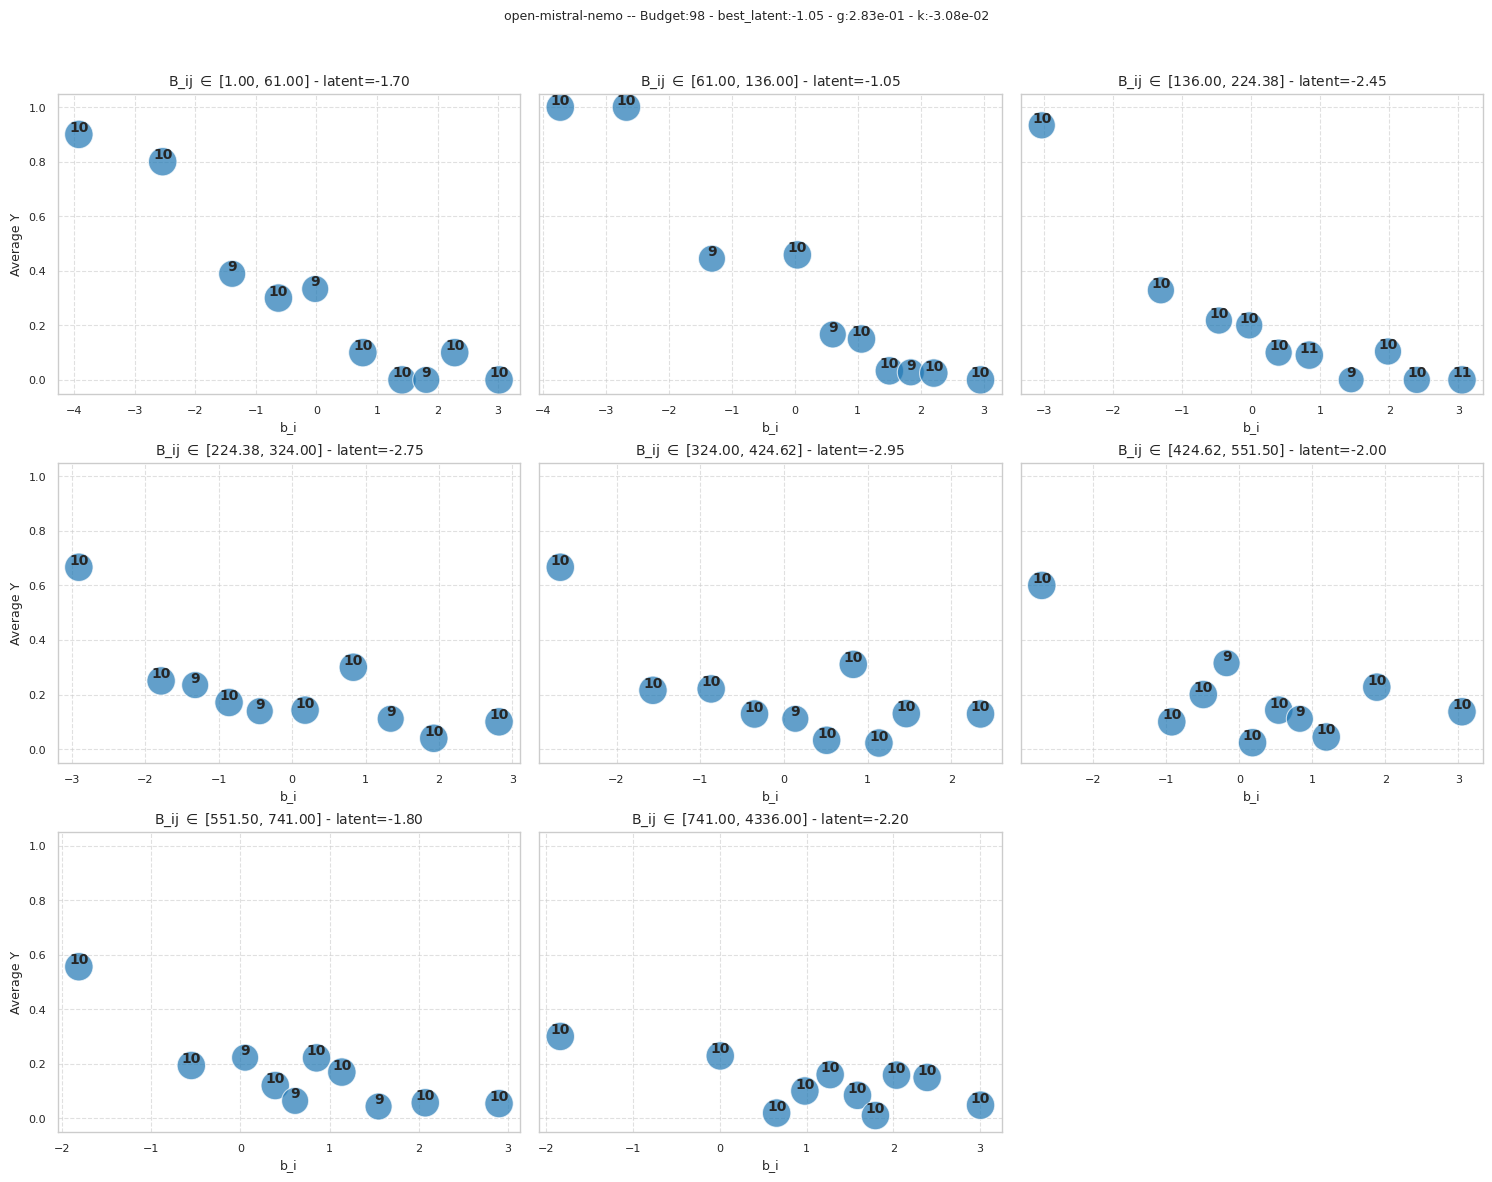

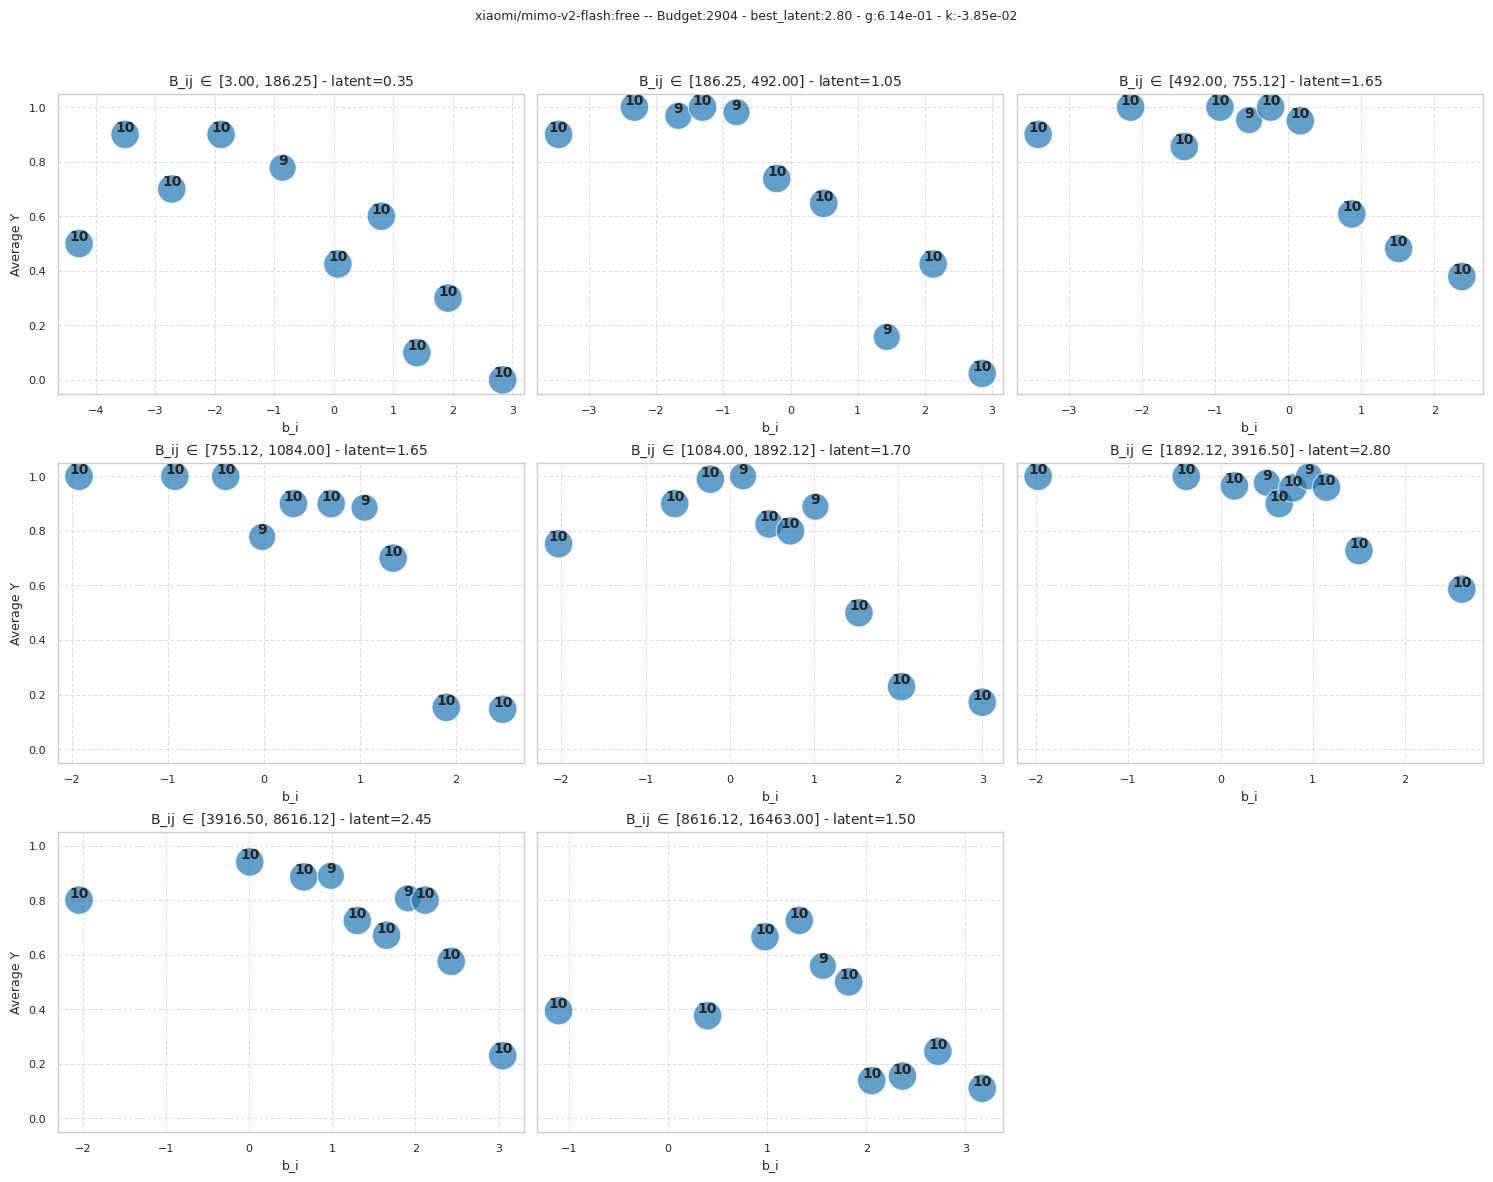

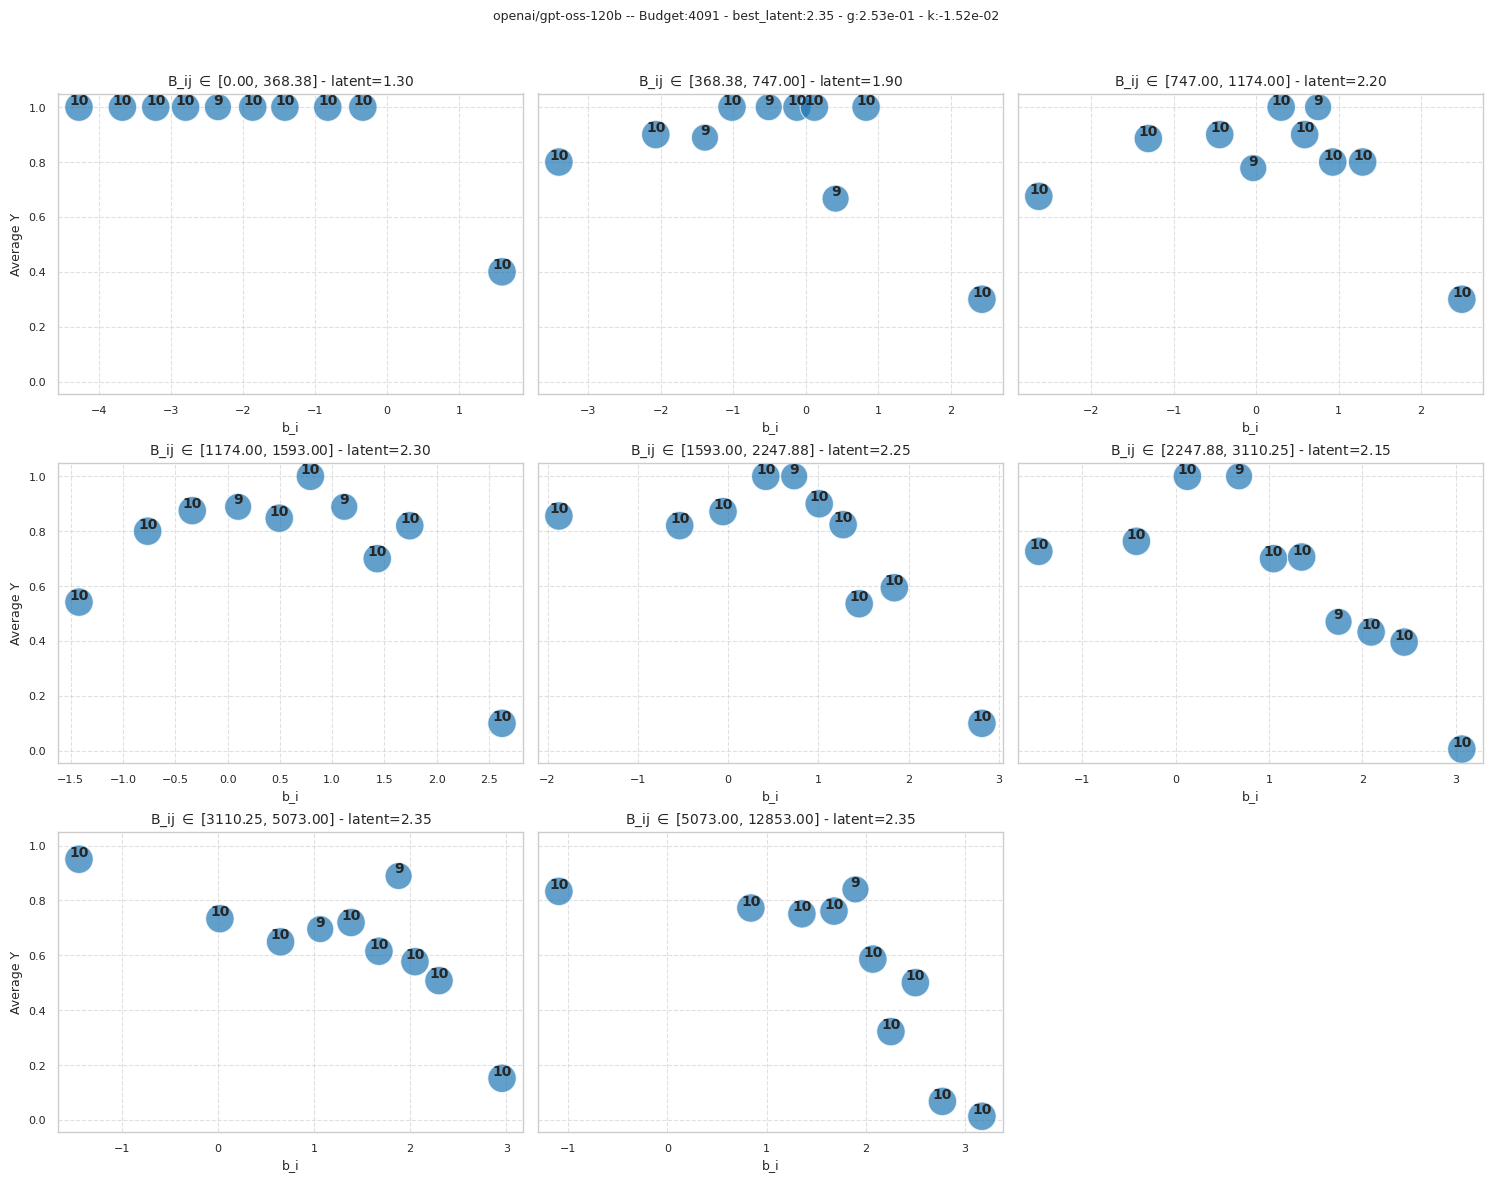

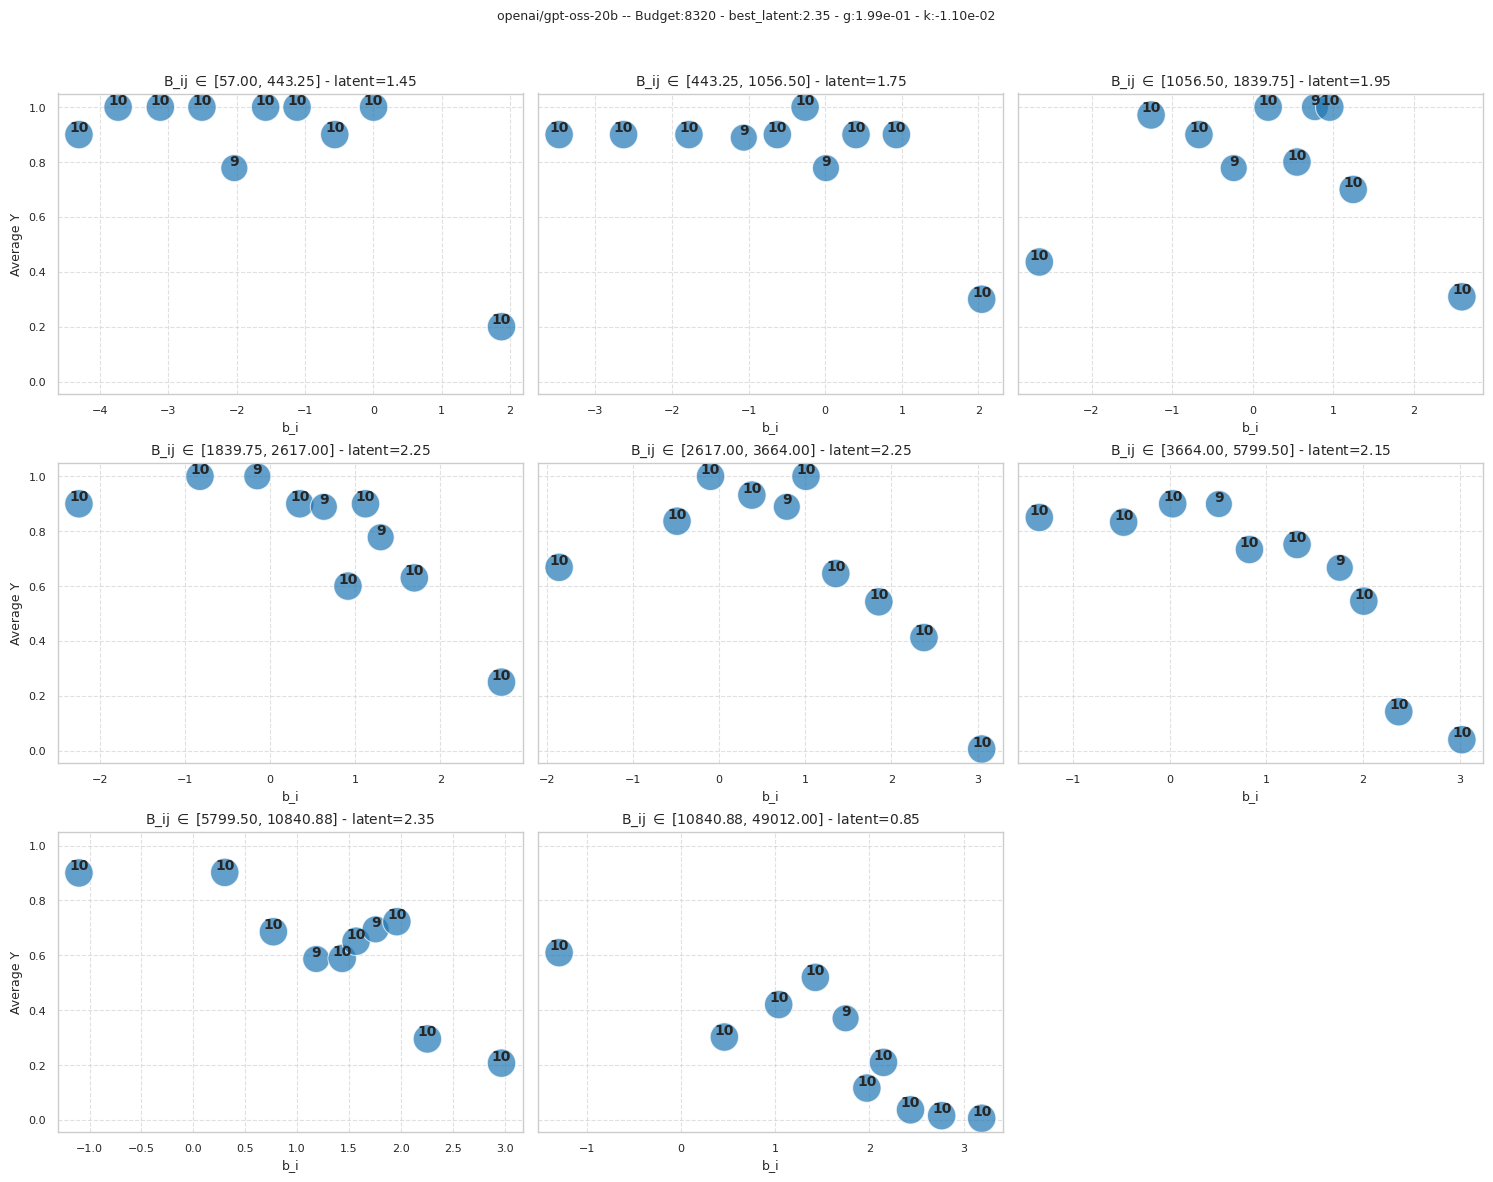

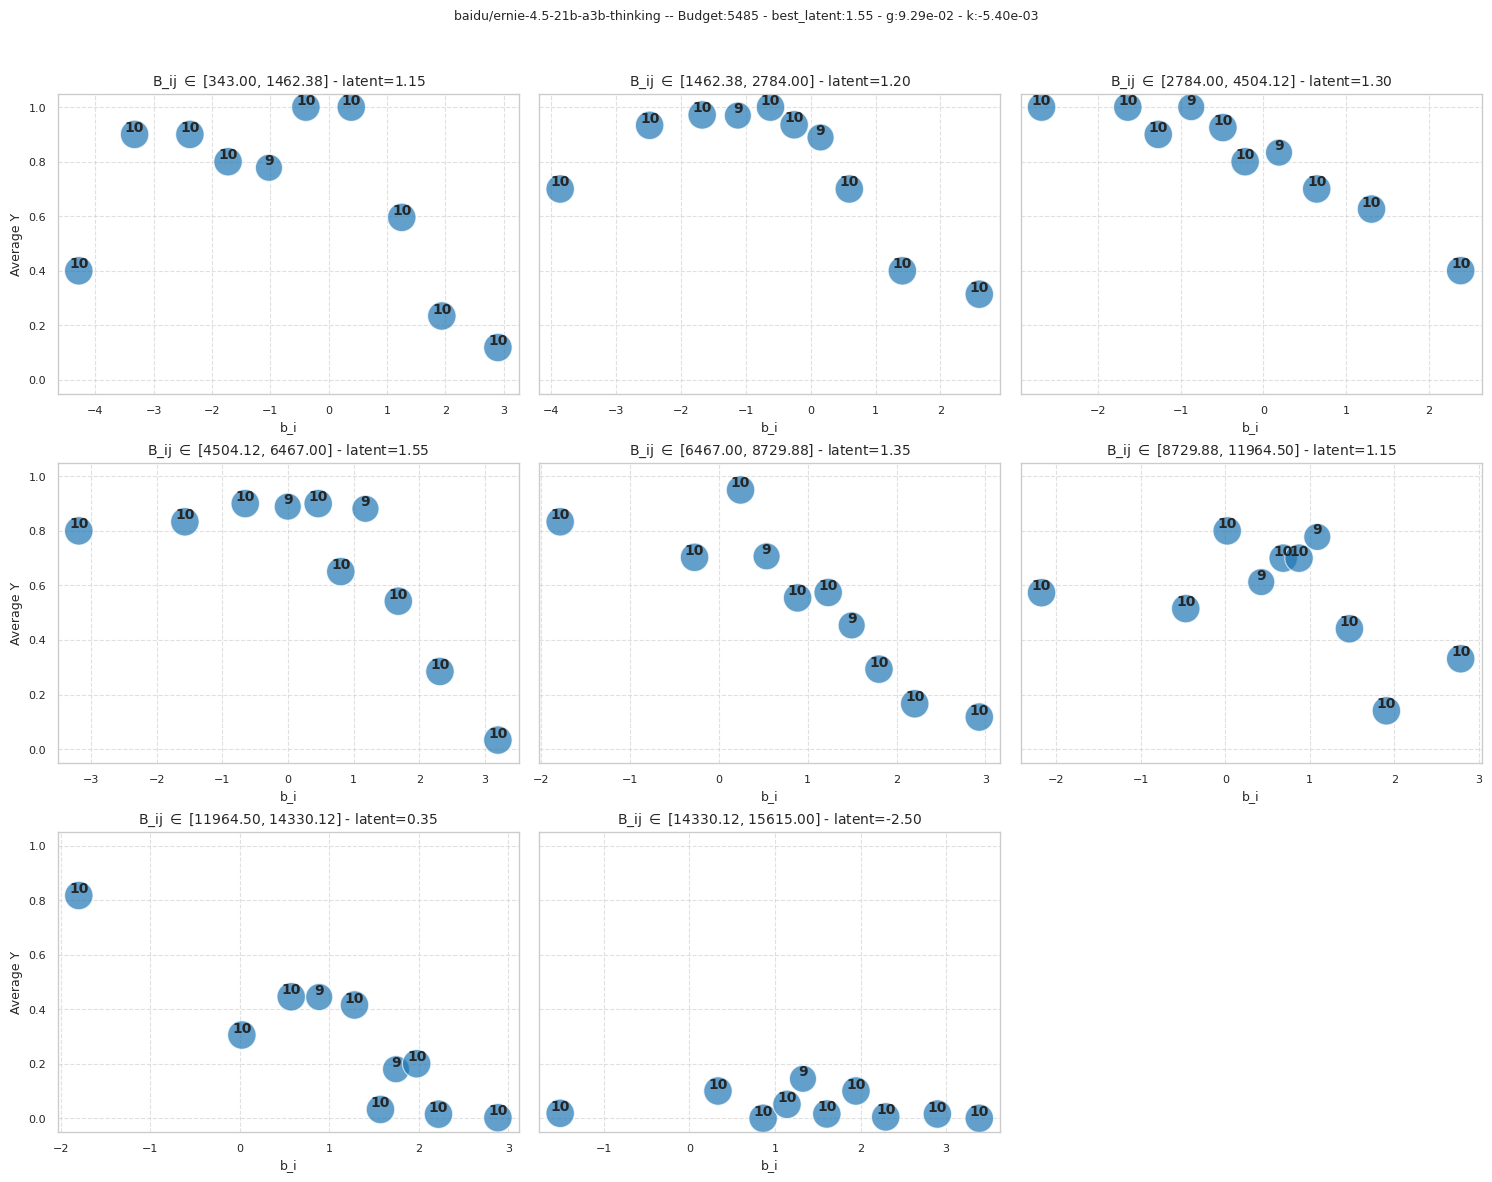

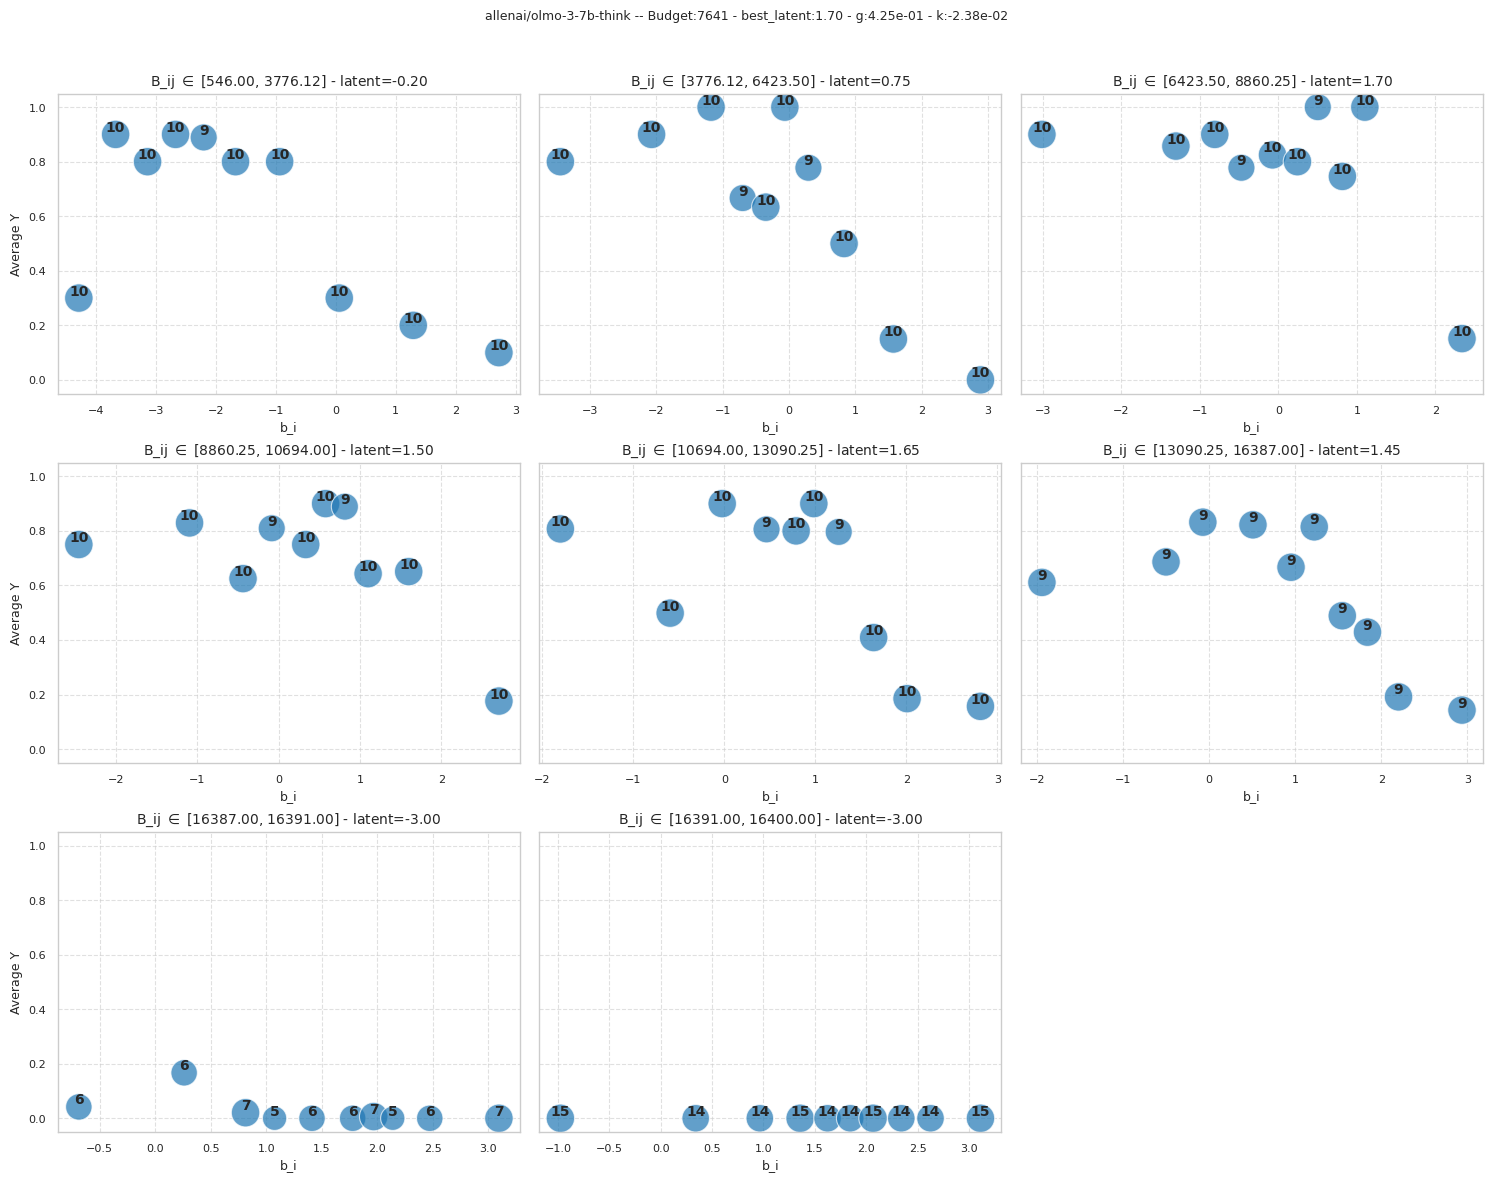

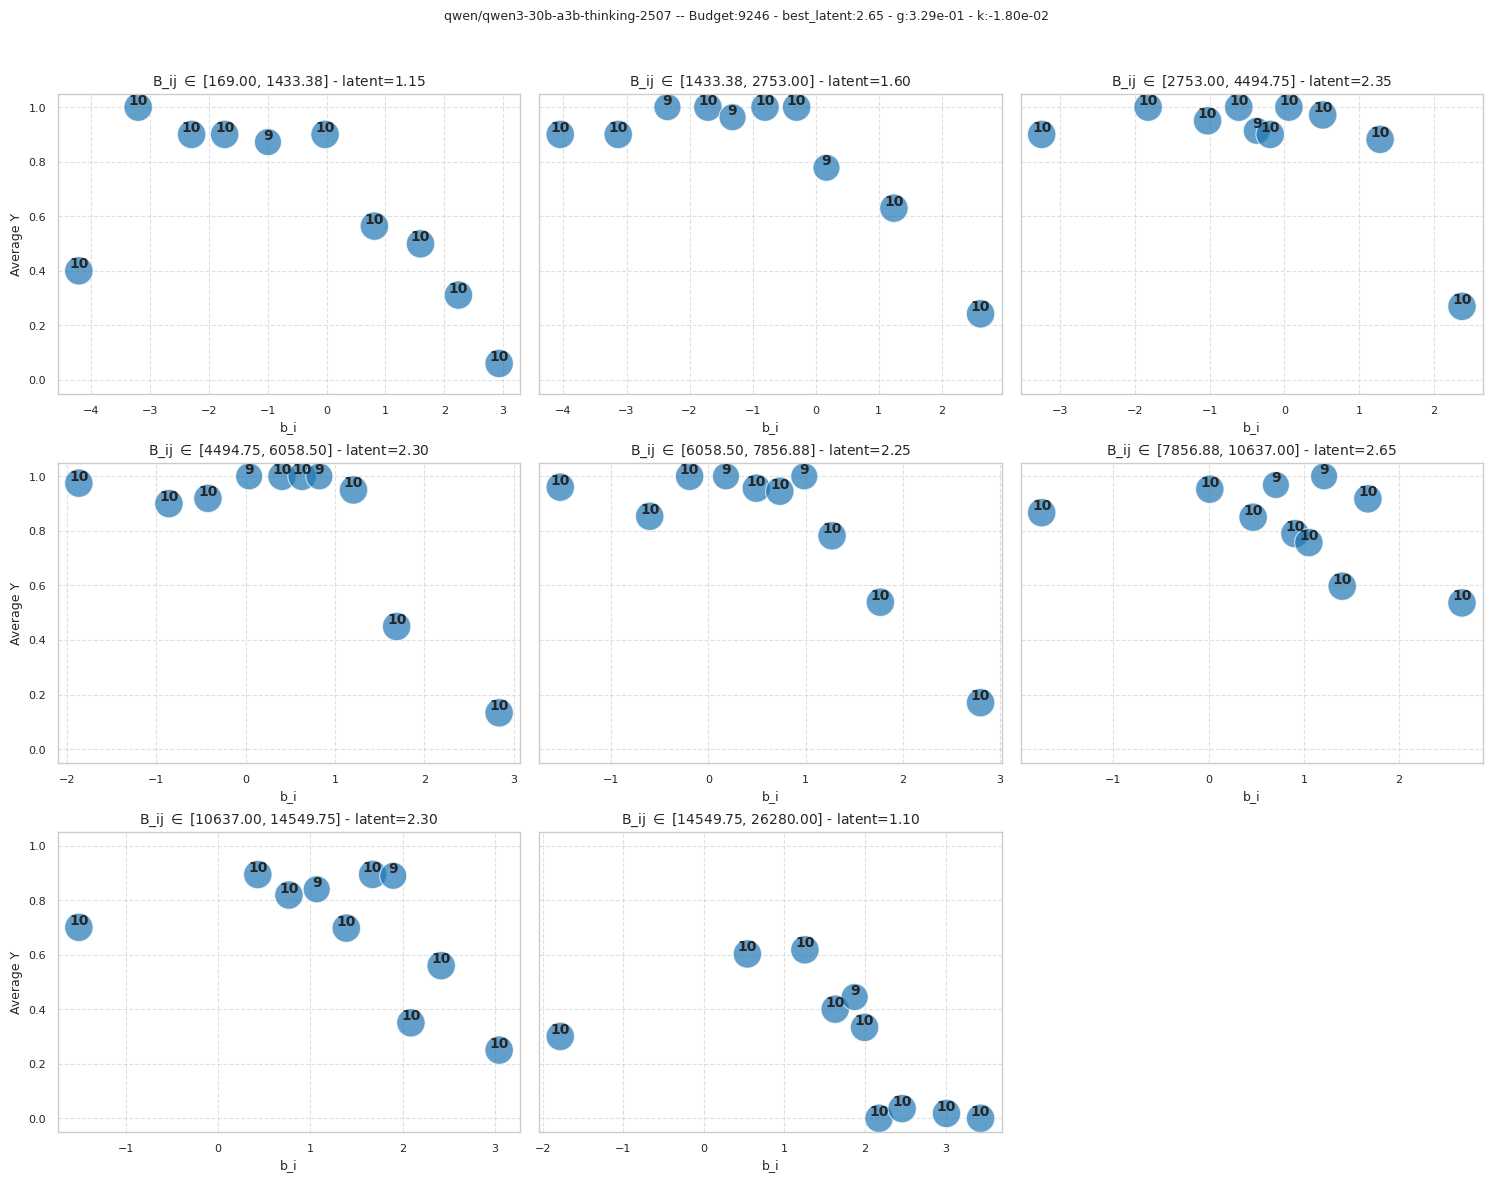

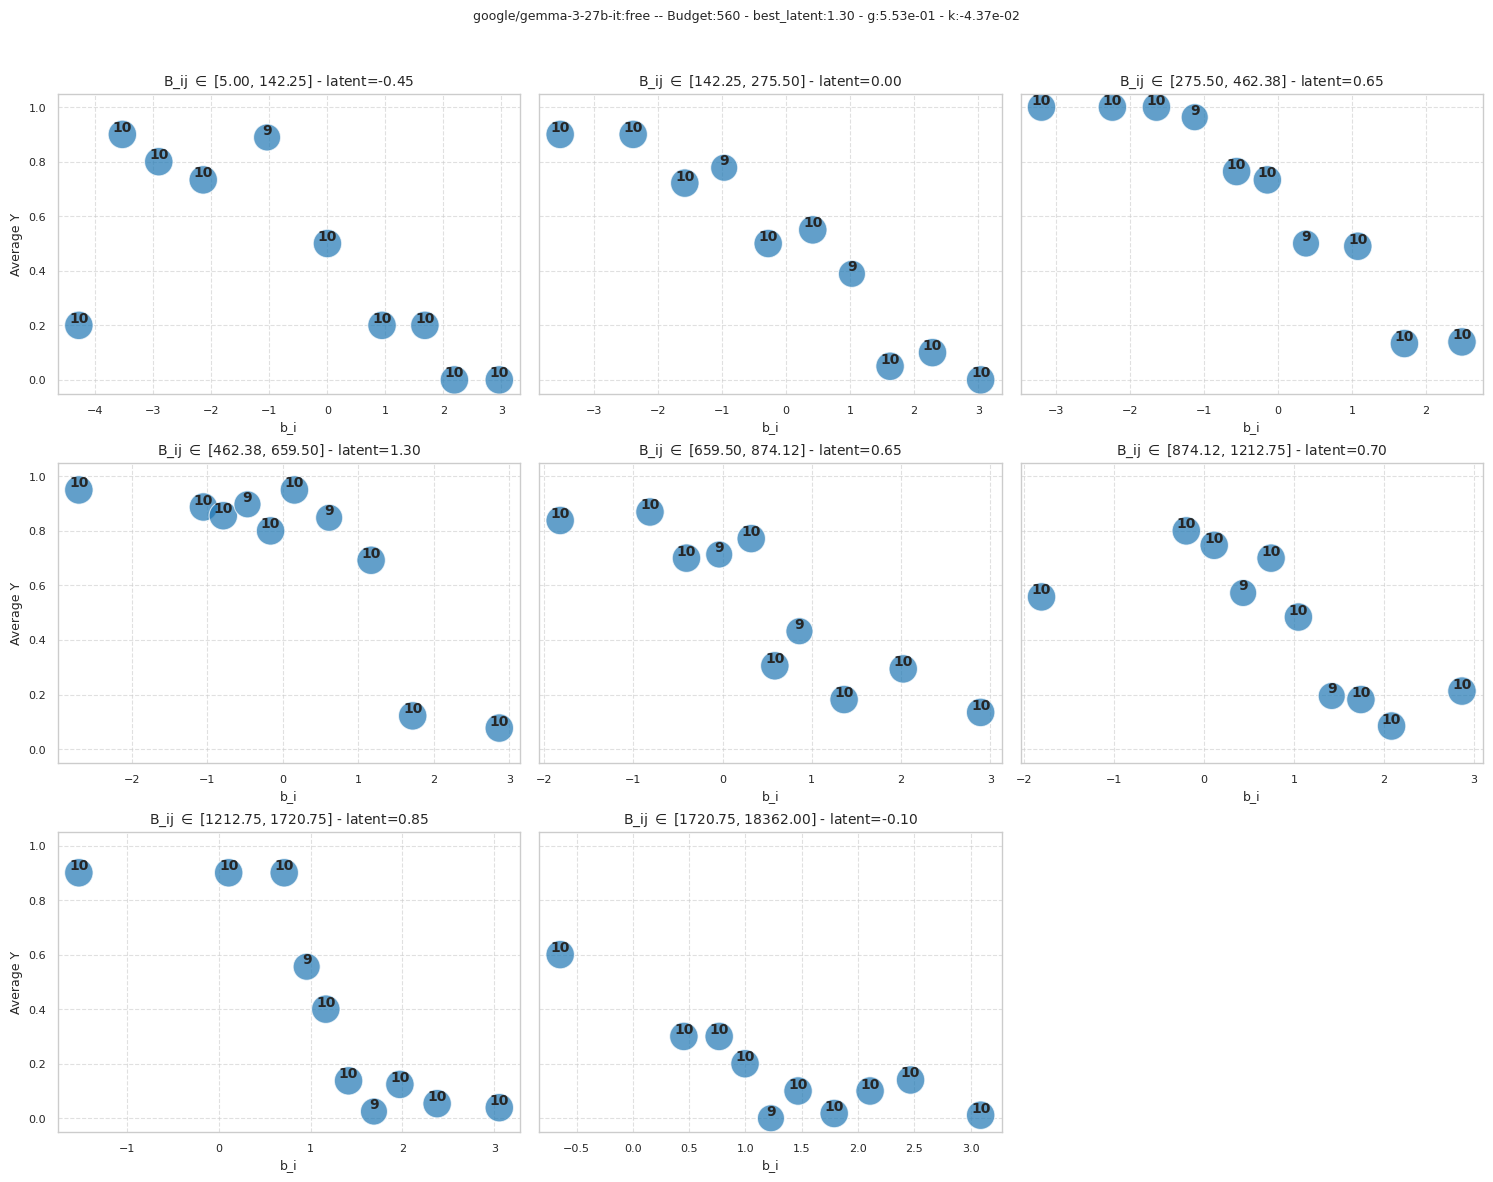

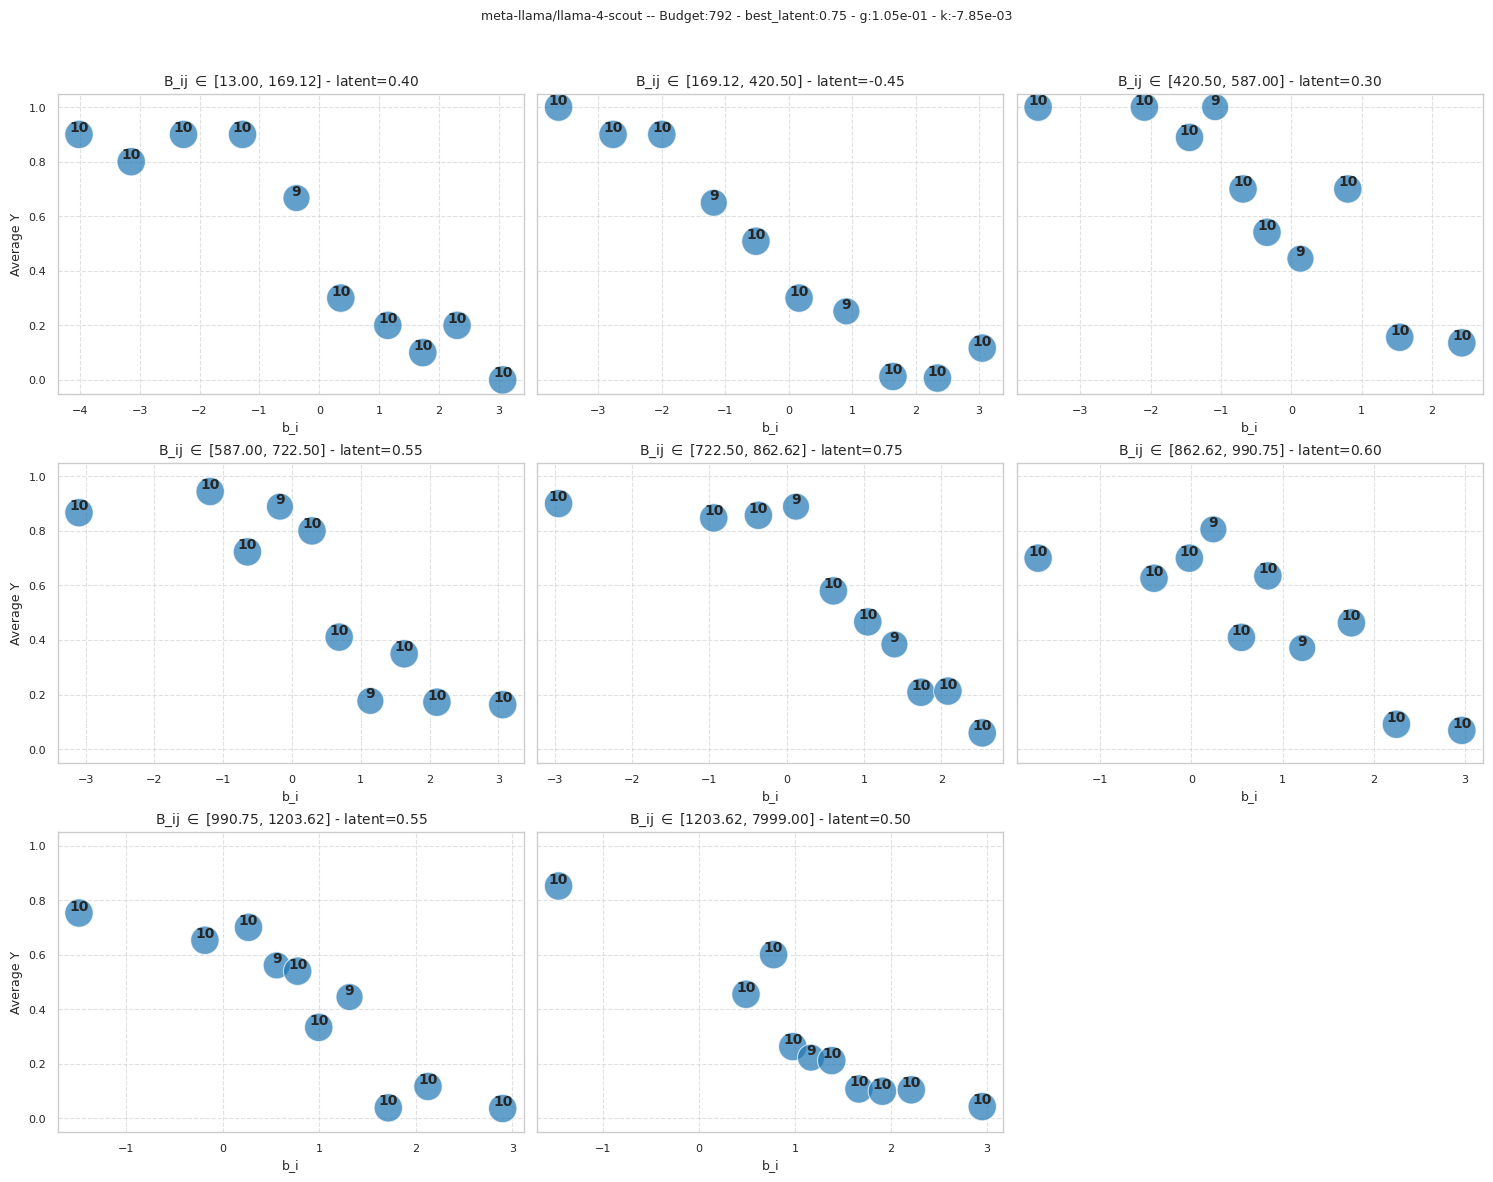

CPU times: user 25 s, sys: 382 ms, total: 25.4 s
Wall time: 25.4 s


In [ ]:
%%time
best_B_j_list = []
best_latent_list = []
gamma_list = []
kappa_list = []

show_fig=False
for j in range(len(model_list)):
    ds2 = {
        'x': np.vstack([fit_results.b_i, B_ij[:,j]]).T,
        'y': Y_ij[:, j],
        'title': f'{model_list[j]}',
        'plot_function_argv' : {
            'min_points_per_bin':3, 
            'use_quantiles':True,
            'x1_label':"b_i",
            'x2_label':"B_ij",
            'y_label':"Average Y",
            'fit_object':fit_results, # valid only if slice_axis is B_ij
            }
        }
    
    if j >= 33: show_fig = True # show only some figures to save space and memory

    ret_dict = plot_sliced_bins(ds2['x'], ds2['y'], slice_axis=1, num_slices=8, num_bins_per_slice=10, title=ds2['title'],
                     **ds2['plot_function_argv'], show_fig=show_fig)
    best_B_j_list.append(ret_dict['best_B_j'])
    best_latent_list.append(ret_dict['best_latent'])
    gamma_list.append(ret_dict['gamma'])
    kappa_list.append(ret_dict['kappa'])

In [15]:
posthoc_first_pass_dict = {}
posthoc_first_pass_dict['best_B_j_list'] = best_B_j_list
posthoc_first_pass_dict['best_latent_list'] = best_latent_list
posthoc_first_pass_dict['gamma_list'] = gamma_list
posthoc_first_pass_dict['kappa_list'] = kappa_list

Here, we save our 1st-pass results for the next round of GEM. Not wanting to make this notebook too long, we refer the readers to `fig2_posthoc.ipynb`

In [16]:
joblib.dump(fit_results, 'data/first_pass_fit_results.pkl')
joblib.dump(posthoc_first_pass_dict, 'data/posthoc_first_pass_dict.pkl')

['data/posthoc_first_pass_dict.pkl']